# 04 — Fixed model comparison

After the stage 03 decision to retain the original 30 inputs, compare the notebook 02 baselines with Random Forest and LightGBM. Fit on the same training payments and score only the same selection payments. Time is an input for all fitted models. No tuning, calibration, or evaluation-set scoring occurs here. Profit follows the [approve/cancel scenario](../docs/cost-scenario.md).

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MLFLOW_DISABLE_AGENT_HINT="1")
run = subprocess.run([sys.executable, str(root / "scripts/run_experiments.py")], cwd=root, env=env, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()

               name  average_precision  brier_score  fraud_canceled_recall  legitimate_cancellation_rate  simulated_profit_per_1000
        approve_all           0.001783     0.001780               0.000000                      0.000000               21740.964182
        amount_rule           0.003090          NaN               0.026316                      0.009517               17299.275955
logistic_regression           0.741775     0.000810               0.657895                      0.000305               21811.863741
      random_forest           0.836546     0.000466               0.789474                      0.000188               21841.443575
           lightgbm           0.842098     0.000432               0.789474                      0.000141               21829.362509
Selection only; calibration and evaluation splits were not scored.



In [2]:
report = json.loads((root / "reports/experiment-results.json").read_text())
assert report["metadata"]["evaluated_split"] == "selection"
assert not report["metadata"]["evaluation_split_scored"]
results = pd.DataFrame(report["baseline_results"] + report["results"])
columns = ["name", "rows", "frauds", "average_precision", "brier_score", "fraud_canceled_recall", "legitimate_cancellation_rate", "simulated_total_profit", "simulated_profit_per_1000", "profit_pct_of_maximum"]
display(results[columns].round(5).sort_values("simulated_profit_per_1000", ascending=False))

,name,rows,frauds,average_precision,brier_score,fraud_canceled_recall,legitimate_cancellation_rate,simulated_total_profit,simulated_profit_per_1000,profit_pct_of_maximum
3,random_forest,42632,76,0.83655,0.00047,0.78947,0.00019,931144.4225,21841.44358,99.12698
4,lightgbm,42632,76,0.84210,0.00043,0.78947,0.00014,930629.3825,21829.36251,99.07215
2,logistic_regression,42632,76,0.74178,0.00081,0.65789,0.00031,929883.3750,21811.86374,98.99273
0,approve_all,42632,76,0.00178,0.00178,0.00000,0.00000,926860.7850,21740.96418,98.67095
1,amount_rule,42632,76,0.00309,NaN,0.02632,0.00952,737502.7325,17299.27595,78.51244


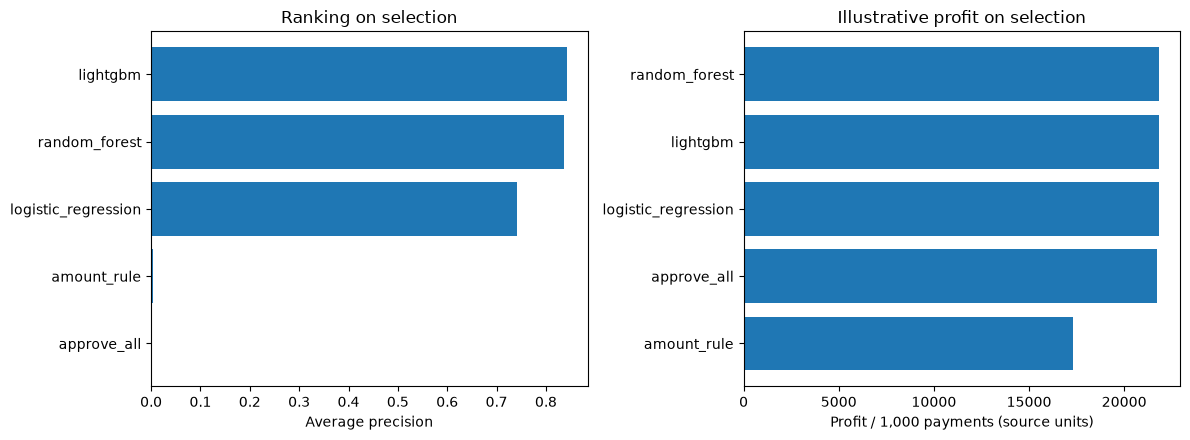

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ordered = results.sort_values("average_precision", ascending=True)
axes[0].barh(ordered.name, ordered.average_precision)
axes[0].set(title="Ranking on selection", xlabel="Average precision")
ordered = results.sort_values("simulated_profit_per_1000", ascending=True)
axes[1].barh(ordered.name, ordered.simulated_profit_per_1000)
axes[1].set(title="Illustrative profit on selection", xlabel="Profit / 1,000 payments (source units)")
fig.tight_layout()
figure_path = root / "reports/figures/experiment-selection-comparison.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

**Interpretation:** Ranking and the fixed 0.20 profit threshold answer different questions. Probabilities have not been calibrated, so the profit ordering is provisional. Prefer the candidate with stronger selection evidence for subsequent calibration; keep evaluation reserved. Full-dataset EDA and earlier experiments exposed the evaluation population before this protocol.